In [6]:
import os, sys

def _first_existing(cands, what):
    for c in cands:
        if os.path.exists(c):
            return c
    raise FileNotFoundError(f"{what}: не найдено ни одного из путей {cands} (cwd = {os.getcwd()})")

ASHIROV_ROOT = next((p for p in ("./ashirov/ashirov", "./ashirov") if os.path.isdir(p + "/tuned-lens")), "./ashirov")
TUNED_LENS_AR_CODE = _first_existing(
    [f"{ASHIROV_ROOT}/tuned-lens/ar-tuned_lens-repo", "./tuned-lens/ar-tuned_lens-repo", "./train_tuned_lens/tuned-lens"],
    "код tuned_lens (папка, внутри которой лежит пакет tuned_lens/)")
TUNED_LENS_DIFF_CODE = _first_existing(
    [f"{ASHIROV_ROOT}/tuned-lens/diffusion-tuned_lens", "./tuned-lens/diffusion-tuned_lens", "./train_tuned_lens/tuned-lens4diffusion"],
    "код tuned_lens_diffusion (папка, внутри которой лежит пакет tuned_lens_diffusion/)")
for _d in (TUNED_LENS_AR_CODE, TUNED_LENS_DIFF_CODE):
    if _d not in sys.path:
        sys.path.append(_d)

from tuned_lens.nn import TunedLens
from tuned_lens_diffusion import DiffusionTunedLens, lens_logits

LLAMA_TUNED_LENS_PATH = _first_existing(
    [f"{TUNED_LENS_AR_CODE}/train_lenses/meta-llama/Llama-3.1-8B-Instruct"], "tuned-lens Llama")
LLADA_TUNED_LENS_PATH = _first_existing(
    [f"{TUNED_LENS_DIFF_CODE}/train_lenses/GSAI-ML/LLaDA-8B-Instruct"], "tuned-lens LLaDA")

LLADA_J_LENS_PATH = _first_existing(
    ["./new_llada_diffusion_lens_merged_1000.pt", "./lens/new_llada_diffusion_lens_merged_1000.pt"], "J-линза LLaDA merged_1000")
LLAMA_J_LENS_PATH = _first_existing(
    ["./llama_jacobian_lens_1000.pt", "./Llama-3.1-8B_jacobian_lens.pt"], "J-линза Llama")

for _k in ("TUNED_LENS_AR_CODE", "TUNED_LENS_DIFF_CODE", "LLAMA_TUNED_LENS_PATH", "LLADA_TUNED_LENS_PATH",
           "LLADA_J_LENS_PATH", "LLAMA_J_LENS_PATH"):
    print(f"{_k:22s} = {globals()[_k]}")

TUNED_LENS_AR_CODE     = ./ashirov/ashirov/tuned-lens/ar-tuned_lens-repo
TUNED_LENS_DIFF_CODE   = ./ashirov/ashirov/tuned-lens/diffusion-tuned_lens
LLAMA_TUNED_LENS_PATH  = ./ashirov/ashirov/tuned-lens/ar-tuned_lens-repo/train_lenses/meta-llama/Llama-3.1-8B-Instruct
LLADA_TUNED_LENS_PATH  = ./ashirov/ashirov/tuned-lens/diffusion-tuned_lens/train_lenses/GSAI-ML/LLaDA-8B-Instruct
LLADA_J_LENS_PATH      = ./new_llada_diffusion_lens_merged_1000.pt
LLAMA_J_LENS_PATH      = ./llama_jacobian_lens_1000.pt


In [7]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import json
from tqdm import tqdm

import jlens
from jlens import Layout
jlens.configure_logging()

import os
from jlens.diffusion_corpus import get_mask_token_id, MASK_ID

In [ ]:
import random

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [9]:
device = "cuda:0"

In [10]:
base_path = "./jacobian-lens/data/evaluations/"
path2data = [
    base_path + fn
    for fn in os.listdir(base_path)
    if fn.endswith(".json")
]

path2data

['./jacobian-lens/data/evaluations/lens-eval-association.json',
 './jacobian-lens/data/evaluations/lens-eval-multihop.json',
 './jacobian-lens/data/evaluations/lens-eval-multilingual.json',
 './jacobian-lens/data/evaluations/lens-eval-order-ops.json',
 './jacobian-lens/data/evaluations/lens-eval-poetry.json',
 './jacobian-lens/data/evaluations/lens-eval-typo.json']

# prep

Цель — посмотреть какие intermediate обе модели токенизируют одним токеном

valid intermediates

intermediate valid if tokenized by one token, otherwise invalid

In [11]:
intermediates_info = pd.DataFrame()

for model_name in ["meta-llama/Llama-3.1-8B-Instruct", "GSAI-ML/LLaDA-8B-Instruct"]:
    cur_tokenizer = AutoTokenizer.from_pretrained(model_name)

    for path2file in path2data:
        with open(path2file, "r", encoding="utf-8") as f:
            cur_eval = json.load(f)

        eval_file_name = path2file.split("/")[-1].split(".")[0]

        cur_states = [
            len(
                cur_tokenizer(intermediate, add_special_tokens=False)["input_ids"]
            ) == 1

            for test in cur_eval["items"]
            for intermediate in test["intermediates"]
        ]

        cur_num = sum(cur_states)
        cur_denum = len(cur_states)

        params = {
            "model_name": [model_name.split("/")[1]],
            "eval_file_name": [eval_file_name],
            "eval_name": [eval_file_name.replace("lens-eval-", "")],
            "valid_intermediates (not unq)": [cur_num],
            "intermediates_cnt (not unq)": [cur_denum],
            "frac": [np.around(cur_num / cur_denum, 5)]
        }
        intermediates_info = pd.concat([intermediates_info, pd.DataFrame(params)], ignore_index=True)

intermediates_info.sort_values(by=["eval_name", "model_name"], ascending=[True, False], ignore_index=True)

,model_name,eval_file_name,eval_name,valid_intermediates (not unq),intermediates_cnt (not unq),frac
0,Llama-3.1-8B-Instruct,lens-eval-association,association,56,102,0.54902
1,LLaDA-8B-Instruct,lens-eval-association,association,57,102,0.55882
2,Llama-3.1-8B-Instruct,lens-eval-multihop,multihop,89,103,0.86408
3,LLaDA-8B-Instruct,lens-eval-multihop,multihop,83,103,0.80583
4,Llama-3.1-8B-Instruct,lens-eval-multilingual,multilingual,337,428,0.78738
5,LLaDA-8B-Instruct,lens-eval-multilingual,multilingual,340,428,0.79439
6,Llama-3.1-8B-Instruct,lens-eval-order-ops,order-ops,67,110,0.60909
7,LLaDA-8B-Instruct,lens-eval-order-ops,order-ops,45,110,0.40909
8,Llama-3.1-8B-Instruct,lens-eval-poetry,poetry,88,98,0.89796
9,LLaDA-8B-Instruct,lens-eval-poetry,poetry,88,98,0.89796


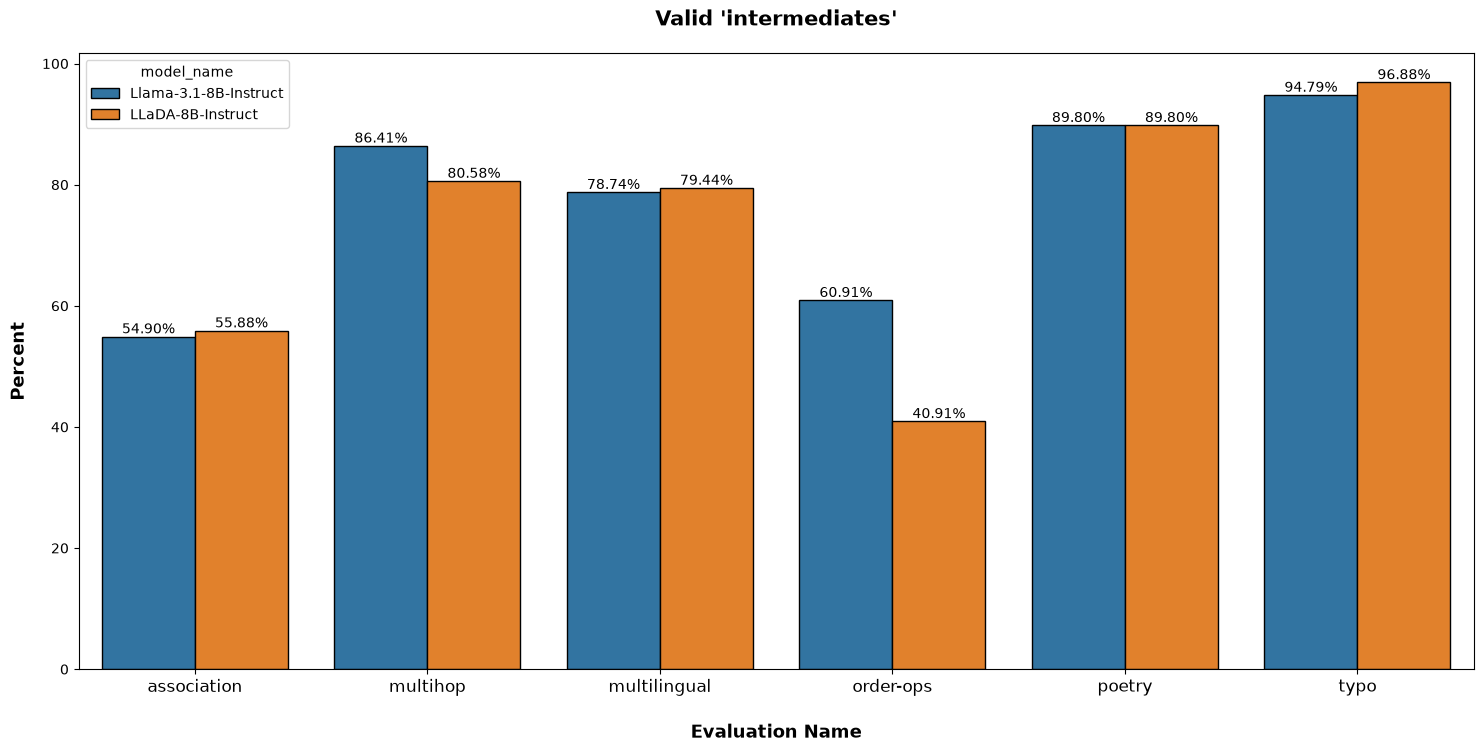

In [12]:
intermediates_info["percent"] = intermediates_info["frac"] * 100

plt.figure(figsize=(18, 8))
ax = sns.barplot(data=intermediates_info, x="eval_name", y="percent", hue="model_name", edgecolor="black")

ax.set_xlabel("Evaluation Name", fontsize=13, fontweight="bold", labelpad=20)
ax.set_ylabel("Percent", fontsize=13, fontweight="bold", labelpad=10)
ax.tick_params(axis="x", labelsize=12)
ax.set_title("Valid 'intermediates'", fontsize=15, fontweight="bold", pad=20)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

например, среди всех multilingual intermedaites — Llama-3.1-8B-Instruct может токенизировать одним токеном только 78.74% записей

---

valid tests

True if exist at least one valid intermediate per test, False otherwise 

In [13]:
tests_info = pd.DataFrame()

for model_name in ["meta-llama/Llama-3.1-8B-Instruct", "GSAI-ML/LLaDA-8B-Instruct"]:
    cur_tokenizer = AutoTokenizer.from_pretrained(model_name)

    for path2file in path2data:
        with open(path2file, "r", encoding="utf-8") as f:
            cur_eval = json.load(f)

        eval_file_name = path2file.split("/")[-1].split(".")[0]

        cur_tests = [test for test in cur_eval["items"]]

        cur_num = sum([
            any([
                len(
                    cur_tokenizer(intermediate, add_special_tokens=False)["input_ids"]
                ) == 1
                for intermediate in test["intermediates"]
            ])

            for test in cur_tests
        ])
        cur_denum = len(cur_tests)

        params = {
            "model_name": [model_name.split("/")[1]],
            "eval_file_name": [eval_file_name],
            "eval_name": [eval_file_name.replace("lens-eval-", "")],
            "valid_tests": [cur_num],
            "tests_cnt": [cur_denum],
            "frac": [np.around(cur_num / cur_denum, 5)]
        }
        tests_info = pd.concat([tests_info, pd.DataFrame(params)], ignore_index=True)

tests_info.sort_values(by=["eval_name", "model_name"], ascending=[True, False], ignore_index=True)

,model_name,eval_file_name,eval_name,valid_tests,tests_cnt,frac
0,Llama-3.1-8B-Instruct,lens-eval-association,association,56,102,0.54902
1,LLaDA-8B-Instruct,lens-eval-association,association,57,102,0.55882
2,Llama-3.1-8B-Instruct,lens-eval-multihop,multihop,79,93,0.84946
3,LLaDA-8B-Instruct,lens-eval-multihop,multihop,73,93,0.78495
4,Llama-3.1-8B-Instruct,lens-eval-multilingual,multilingual,107,107,1.00000
5,LLaDA-8B-Instruct,lens-eval-multilingual,multilingual,107,107,1.00000
6,Llama-3.1-8B-Instruct,lens-eval-order-ops,order-ops,55,55,1.00000
7,LLaDA-8B-Instruct,lens-eval-order-ops,order-ops,42,55,0.76364
8,Llama-3.1-8B-Instruct,lens-eval-poetry,poetry,88,98,0.89796
9,LLaDA-8B-Instruct,lens-eval-poetry,poetry,88,98,0.89796


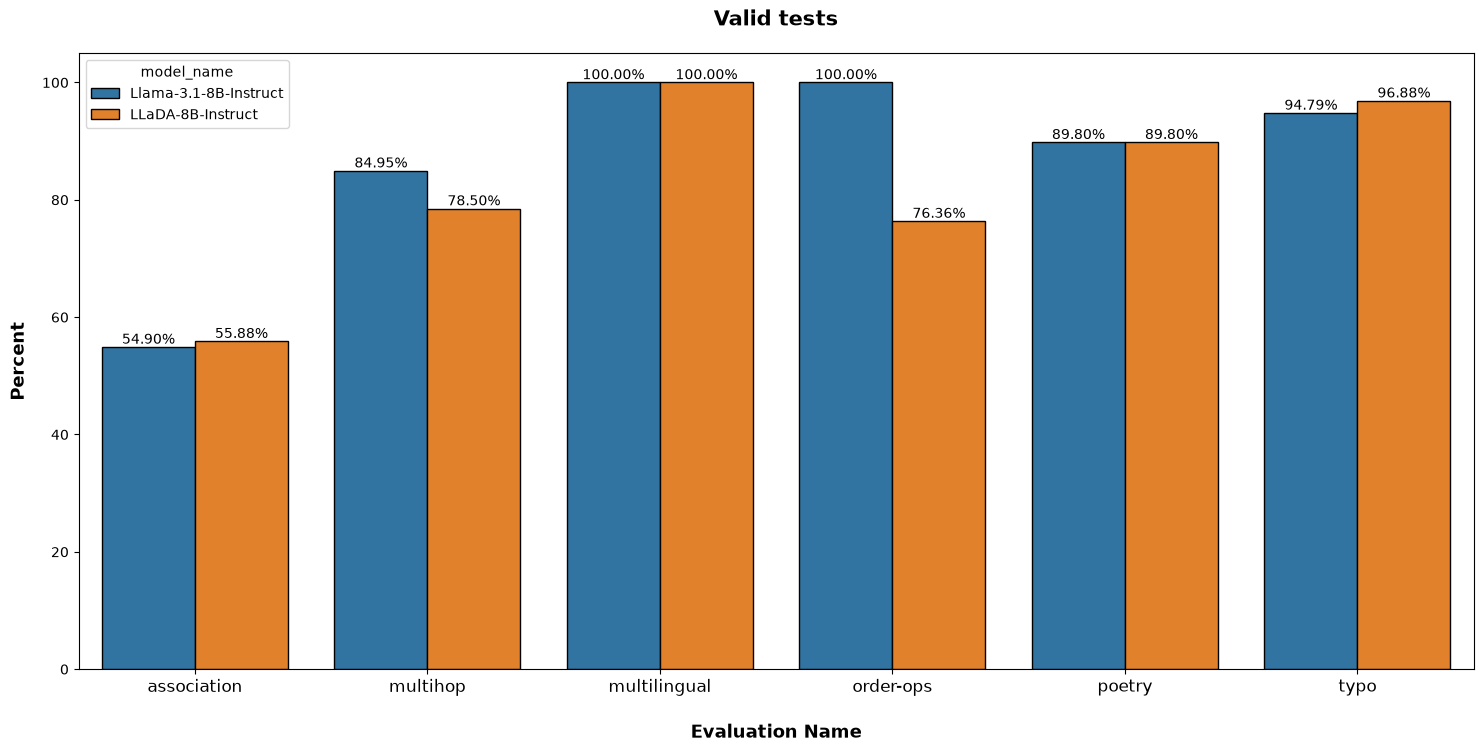

In [14]:
tests_info["percent"] = tests_info["frac"] * 100

plt.figure(figsize=(18, 8))
ax = sns.barplot(data=tests_info, x="eval_name", y="percent", hue="model_name", edgecolor="black")

ax.set_xlabel("Evaluation Name", fontsize=13, fontweight="bold", labelpad=20)
ax.set_ylabel("Percent", fontsize=13, fontweight="bold", labelpad=10)
ax.tick_params(axis="x", labelsize=12)
ax.set_title("Valid tests", fontsize=15, fontweight="bold", pad=20)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

например, среди всех typo тестов — Llama-3.1-8B-Instruct может токенизировать хотя бы 1 intermediate одним токеном в 94.79 % тестов

---

general valid tests

True if exist at least one general valid intermediate per test, False otherwise

general valid intermediate — Llama & LLaDA tokenized intermediate by one token

In [15]:
intersection_tests_info = pd.DataFrame()

llama_tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-3.1-8B-Instruct")
llada_tokenizer = AutoTokenizer.from_pretrained("GSAI-ML/LLaDA-8B-Instruct")

general_valid_intermediates = set()

for path2file in path2data:
    with open(path2file, "r", encoding="utf-8") as f:
        cur_eval = json.load(f)

    eval_file_name = path2file.split("/")[-1].split(".")[0]

    cur_denum = 0
    cur_num = []

    for test in cur_eval["items"]:
        cur_denum += 1
        cur_state_of_test = []

        for intermediate in test["intermediates"]:
            if (
                (len(llama_tokenizer(intermediate, add_special_tokens=False)["input_ids"]) == 1)
                and (len(llada_tokenizer(intermediate, add_special_tokens=False)["input_ids"]) == 1)
            ):
                cur_state_of_test.append(True)
                general_valid_intermediates.add(intermediate)

        cur_num.append(any(cur_state_of_test))

    cur_num = sum(cur_num)

    params = {
        "eval_file_name": [eval_file_name],
        "eval_name": [eval_file_name.replace("lens-eval-", "")],
        "general_valid_tests": [cur_num],
        "tests_cnt": [cur_denum],
        "frac": [np.around(cur_num / cur_denum, 5)]
    }
    intersection_tests_info = pd.concat([intersection_tests_info, pd.DataFrame(params)], ignore_index=True)

intersection_tests_info.sort_values(by=["eval_name"], ascending=[True], ignore_index=True)

,eval_file_name,eval_name,general_valid_tests,tests_cnt,frac
0,lens-eval-association,association,53,102,0.51961
1,lens-eval-multihop,multihop,70,93,0.75269
2,lens-eval-multilingual,multilingual,107,107,1.00000
3,lens-eval-order-ops,order-ops,42,55,0.76364
4,lens-eval-poetry,poetry,87,98,0.88776
5,lens-eval-typo,typo,90,96,0.93750


In [16]:
len(general_valid_intermediates)

305

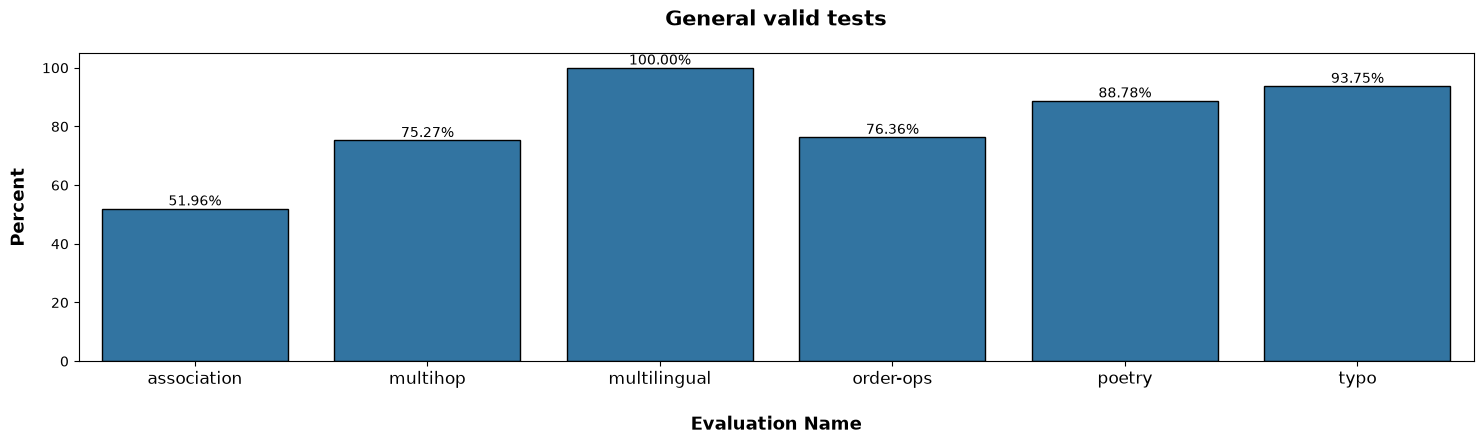

In [17]:
intersection_tests_info["percent"] = intersection_tests_info["frac"] * 100

plt.figure(figsize=(18, 4))
ax = sns.barplot(data=intersection_tests_info, x="eval_name", y="percent", edgecolor="black")

ax.set_xlabel("Evaluation Name", fontsize=13, fontweight="bold", labelpad=20)
ax.set_ylabel("Percent", fontsize=13, fontweight="bold", labelpad=10)
ax.tick_params(axis="x", labelsize=12)
ax.set_title("General valid tests", fontsize=15, fontweight="bold", pad=20)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

например, среди всех typo тестов — Llama-3.1-8B-Instruct и LLaDA-8B-Instruct одновременно могут токенизировать хотя бы 1 intermediate одним токеном в 94.79 % тестов

# evaluation

линза читается на последней позиции промпта (для LLaDA — на дописанном `[MASK]`)

поддерживается, как подсчет метрик на intermediates, которые обе модели токенизирует одним токеном, так и на всех intermediates с взятием первого токена для сравнения

LLaDA load

In [18]:
model_name = "GSAI-ML/LLaDA-8B-Instruct"
llada_tokenizer = AutoTokenizer.from_pretrained(model_name)
hf_model = AutoModelForCausalLM.from_pretrained(
    model_name, trust_remote_code=True, dtype=torch.bfloat16,
).to(device)

class WrappedLLaDA:
    def __init__(self, model):
        self.model = model
        self.blocks = model.transformer.blocks
        self.ln_f = model.transformer.ln_f
        self.wte = model.transformer.wte

    def forward(self, input_ids, **kwargs):
        return self.model(input_ids, **kwargs)

    def __call__(self, input_ids, **kwargs):
        return self.forward(input_ids, **kwargs)

hf_model.text_module = WrappedLLaDA(hf_model.model)
hf_model.lm_head = hf_model.model.transformer.ff_out

layout = Layout(
    path="text_module",
    layers="blocks",
    norm="ln_f",
    embed="wte",
    lm_head="lm_head"
)

llada_model = jlens.from_hf(hf_model, llada_tokenizer, layout=layout)
llada_j_lens = jlens.JacobianLens.load(LLADA_J_LENS_PATH)
print("LLaDA J-lens:", LLADA_J_LENS_PATH)

mask_id = get_mask_token_id(hf_model, fallback=MASK_ID)
print(f"mask_id = {mask_id}")

Loading checkpoint shards: 100%|██████████| 6/6 [00:00<00:00, 11.17it/s]


LLaDA J-lens: ./new_llada_diffusion_lens_merged_1000.pt
mask_id = 126336


In [19]:
llada_hf_model = hf_model
llada_tuned_lens = DiffusionTunedLens.load(
    LLADA_TUNED_LENS_PATH, hf_model=llada_hf_model,
).to(device).eval()
print(
    "LLaDA tuned lens:",
    llada_tuned_lens.config.num_hidden_layers,
    "layers, n_prompts =",
    llada_tuned_lens.config.n_prompts,
)

LLaDA tuned lens: 32 layers, n_prompts = 1000


Llama load

In [20]:
model_name = "meta-llama/Llama-3.1-8B-Instruct"
llama_tokenizer = AutoTokenizer.from_pretrained(model_name)
hf_model = AutoModelForCausalLM.from_pretrained(
    model_name, trust_remote_code=True, dtype=torch.bfloat16,
).to(device)

llama_model = jlens.from_hf(hf_model, llama_tokenizer)
llama_j_lens = jlens.JacobianLens.load(LLAMA_J_LENS_PATH)

Loading checkpoint shards: 100%|██████████| 4/4 [00:00<00:00,  7.88it/s]


In [21]:
llama_hf_model = hf_model
llama_tuned_lens = TunedLens.from_model_and_pretrained(
    llama_hf_model, LLAMA_TUNED_LENS_PATH,
).to(device).eval()
print("Llama tuned lens:", llama_tuned_lens.config.num_hidden_layers, "layers")

Llama tuned lens: 32 layers


In [22]:
def tokenizer_call(prompt, tokenizer, mode):
    match mode:
        case "get_intermediate_token_id":
            return tokenizer(prompt, add_special_tokens=False)["input_ids"][0]

        case _:
            raise ValueError(f"get mode={mode}")

In [23]:
from typing import Callable

def run_eval_test(
    model_call: Callable[[str, list[int]], tuple],
    tokenizer_call: Callable[[str, str], int],
    eval_data: dict,
    eval_name: str,
    at_k: list[int],
    general_valid_intermediates: set,
    model_name4tqdm: str,
    use_jacobian: bool,
    token_mode: str,
    method: str,
):
    assert eval_name in {
        'multilingual', 'typo', 'association', 'poetry', 'multihop', 'order-ops',
    }, f"get {eval_name}"

    assert token_mode in {
        "single_token", "first_token"
    }, f"get {token_mode}"

    assert len(at_k) > 1, f"len at_k must be greater than 1"

    at_k = sorted(at_k)

    pass_at_k = {
        k: 0
        for k in at_k
    }
    max_k = max(at_k)
    denum = 0

    for test in tqdm(eval_data["items"], desc=f"{model_name4tqdm}: eval={eval_name}, method={method}, token_mode={token_mode}"):
        is_valid = False

        min_rank = float("inf")

        position = [-1]
        jlens_logits, _, _ = model_call(prompt=test["prompt"], positions=position, use_jacobian=use_jacobian)

        model_layer2top_indices = {
            layer_num: logits[0].topk(max_k).indices
            for layer_num, logits in jlens_logits.items()
        }

        for intermediate in test["intermediates"]:
            if (intermediate not in general_valid_intermediates) and (token_mode == "single_token"):
                continue

            is_valid = True
            cur_intermediate_token_id = tokenizer_call(prompt=intermediate, mode="get_intermediate_token_id")

            for top_indices in model_layer2top_indices.values():
                cur_search = (top_indices == cur_intermediate_token_id).nonzero().flatten().tolist()
                assert len(cur_search) <= 1, f"how, get {cur_search}"

                if len(cur_search) == 1:
                    cur_rank = cur_search[0] + 1
                    min_rank = min(min_rank, cur_rank)

        denum += is_valid

        if min_rank != float("inf"):
            for k in pass_at_k.keys():
                if min_rank <= k:
                    pass_at_k[k] += 1

    mn_k = float("inf")
    mx_k = -float("inf")
    pass_at_k_values = []

    for k in at_k:
        mn_k = min(mn_k, k)
        mx_k = max(mx_k, k)

        cur_pass_per_k = np.around(pass_at_k[k] / denum, 5).item()

        pass_at_k[k] = cur_pass_per_k
        pass_at_k_values.append(cur_pass_per_k)

    cur_auc = np.trapezoid(pass_at_k_values, x=at_k)
    perfect_auc = mx_k - mn_k

    norm_auc = np.around(cur_auc / perfect_auc, 3).item()

    return {
        "pass_at_k": pass_at_k,
        "auc": norm_auc,
    }

In [24]:
single_token_results = []
first_token_results = []

workspace_band = list(range(31))

at_k = [1, 5, 20, 100, 200, 500, 1000]

tokenizer_call_llama = lambda prompt, mode: tokenizer_call(prompt=prompt, tokenizer=llama_tokenizer, mode=mode)
tokenizer_call_llada = lambda prompt, mode: tokenizer_call(prompt=prompt, tokenizer=llada_tokenizer, mode=mode)

call_llama_j_lens = lambda prompt, positions, use_jacobian: llama_j_lens.apply(
    llama_model,
    prompt,
    layers=workspace_band,
    positions=positions,
    use_jacobian=use_jacobian,
)

def call_llada_lens(prompt, positions, use_jacobian):
    ids = llada_tokenizer(prompt, return_tensors="pt")["input_ids"].to(llada_model.input_device)
    mask_col = torch.full((1, 1), mask_id, dtype=torch.long, device=llada_model.input_device)
    augmented = torch.cat([ids, mask_col], dim=1)
    mask_position = [augmented.shape[1] - 1]
    return llada_j_lens.apply(llada_model, input_ids=augmented, layers=workspace_band, positions=mask_position, use_jacobian=use_jacobian)

def call_llama_tuned_lens(prompt, positions, use_jacobian=False):
    ids = llama_tokenizer(prompt, return_tensors="pt")["input_ids"].to(device)
    return lens_logits(
        llama_hf_model, llama_tuned_lens,
        input_ids=ids, layers=workspace_band, positions=positions,
    )

def call_llada_tuned_lens(prompt, positions, use_jacobian=False):
    ids = llada_tokenizer(prompt, return_tensors="pt")["input_ids"].to(device)
    mask_col = torch.full((1, 1), mask_id, dtype=torch.long, device=device)
    augmented = torch.cat([ids, mask_col], dim=1)
    return lens_logits(
        llada_hf_model, llada_tuned_lens,
        input_ids=augmented, layers=workspace_band,
        positions=[augmented.shape[1] - 1],
    )

for path2file in path2data:
    with open(path2file, "r", encoding="utf-8") as f:
        cur_eval = json.load(f)

    eval_file_name = path2file.split("/")[-1].split(".")[0]
    eval_name = eval_file_name.replace("lens-eval-", "")

    for token_mode in ["single_token", "first_token"]:
        for method in ["logit-lens", "j-lens", "tuned-lens"]:

            match method:
                case "logit-lens":
                    use_jacobian, llama_call, llada_call = False, call_llama_j_lens, call_llada_lens

                case "j-lens":
                    use_jacobian, llama_call, llada_call = True, call_llama_j_lens, call_llada_lens

                case "tuned-lens":
                    use_jacobian, llama_call, llada_call = False, call_llama_tuned_lens, call_llada_tuned_lens

                case _:
                    raise ValueError(f"get unsupported method: {method}")

            cur_llama_res = run_eval_test(
                model_call=llama_call, tokenizer_call=tokenizer_call_llama,
                eval_data=cur_eval, eval_name=eval_name,
                at_k=at_k, general_valid_intermediates=general_valid_intermediates,
                model_name4tqdm="Llama-3.1-8B-Instruct",
                use_jacobian=use_jacobian,
                token_mode=token_mode,
                method=method,
            )
            params = {
                "eval_file_name": eval_file_name,
                "eval_name": eval_name,
                "model_name": "Llama-3.1-8B-Instruct",
                "method": method,
                "auc": cur_llama_res["auc"]
            }
            params.update({f"pass@{key}": val for key, val in cur_llama_res["pass_at_k"].items()})

            if token_mode == "single_token":
                single_token_results.append(params)
            else:
                first_token_results.append(params)

            cur_llada_res = run_eval_test(
                model_call=llada_call, tokenizer_call=tokenizer_call_llada,
                eval_data=cur_eval, eval_name=eval_name,
                at_k=at_k, general_valid_intermediates=general_valid_intermediates,
                model_name4tqdm="LLaDA-8B-Instruct",
                use_jacobian=use_jacobian,
                token_mode=token_mode,
                method=method,
            )
            params = {
                "eval_file_name": eval_file_name,
                "eval_name": eval_name,
                "model_name": "LLaDA-8B-Instruct",
                "method": method,
                "auc": cur_llada_res["auc"]
            }
            params.update({f"pass@{key}": val for key, val in cur_llada_res["pass_at_k"].items()})

            if token_mode == "single_token":
                single_token_results.append(params)
            else:
                first_token_results.append(params)

    print(flush=True)

Llama-3.1-8B-Instruct: eval=association, method=logit-lens, token_mode=single_token: 100%|██████████| 102/102 [00:25<00:00,  4.02it/s]
LLaDA-8B-Instruct: eval=association, method=logit-lens, token_mode=single_token: 100%|██████████| 102/102 [00:21<00:00,  4.81it/s]
Llama-3.1-8B-Instruct: eval=association, method=j-lens, token_mode=single_token: 100%|██████████| 102/102 [00:43<00:00,  2.33it/s]
LLaDA-8B-Instruct: eval=association, method=j-lens, token_mode=single_token: 100%|██████████| 102/102 [00:28<00:00,  3.55it/s]
Llama-3.1-8B-Instruct: eval=association, method=tuned-lens, token_mode=single_token: 100%|██████████| 102/102 [00:06<00:00, 16.00it/s]
LLaDA-8B-Instruct: eval=association, method=tuned-lens, token_mode=single_token: 100%|██████████| 102/102 [00:06<00:00, 16.08it/s]
Llama-3.1-8B-Instruct: eval=association, method=logit-lens, token_mode=first_token: 100%|██████████| 102/102 [00:08<00:00, 12.15it/s]
LLaDA-8B-Instruct: eval=association, method=logit-lens, token_mode=first_tok


Llama-3.1-8B-Instruct: eval=multihop, method=logit-lens, token_mode=single_token: 100%|██████████| 93/93 [00:07<00:00, 11.95it/s]
LLaDA-8B-Instruct: eval=multihop, method=logit-lens, token_mode=single_token: 100%|██████████| 93/93 [00:06<00:00, 13.96it/s]
Llama-3.1-8B-Instruct: eval=multihop, method=j-lens, token_mode=single_token: 100%|██████████| 93/93 [00:26<00:00,  3.45it/s]
LLaDA-8B-Instruct: eval=multihop, method=j-lens, token_mode=single_token: 100%|██████████| 93/93 [00:26<00:00,  3.53it/s]
Llama-3.1-8B-Instruct: eval=multihop, method=tuned-lens, token_mode=single_token: 100%|██████████| 93/93 [00:05<00:00, 16.18it/s]
LLaDA-8B-Instruct: eval=multihop, method=tuned-lens, token_mode=single_token: 100%|██████████| 93/93 [00:05<00:00, 16.56it/s]
Llama-3.1-8B-Instruct: eval=multihop, method=logit-lens, token_mode=first_token: 100%|██████████| 93/93 [00:07<00:00, 12.35it/s]
LLaDA-8B-Instruct: eval=multihop, method=logit-lens, token_mode=first_token: 100%|██████████| 93/93 [00:06<00:


Llama-3.1-8B-Instruct: eval=multilingual, method=logit-lens, token_mode=single_token: 100%|██████████| 107/107 [00:08<00:00, 12.43it/s]
LLaDA-8B-Instruct: eval=multilingual, method=logit-lens, token_mode=single_token: 100%|██████████| 107/107 [00:07<00:00, 13.93it/s]
Llama-3.1-8B-Instruct: eval=multilingual, method=j-lens, token_mode=single_token: 100%|██████████| 107/107 [00:31<00:00,  3.44it/s]
LLaDA-8B-Instruct: eval=multilingual, method=j-lens, token_mode=single_token: 100%|██████████| 107/107 [00:29<00:00,  3.60it/s]
Llama-3.1-8B-Instruct: eval=multilingual, method=tuned-lens, token_mode=single_token: 100%|██████████| 107/107 [00:06<00:00, 16.23it/s]
LLaDA-8B-Instruct: eval=multilingual, method=tuned-lens, token_mode=single_token: 100%|██████████| 107/107 [00:06<00:00, 16.76it/s]
Llama-3.1-8B-Instruct: eval=multilingual, method=logit-lens, token_mode=first_token: 100%|██████████| 107/107 [00:08<00:00, 12.28it/s]
LLaDA-8B-Instruct: eval=multilingual, method=logit-lens, token_mode=


Llama-3.1-8B-Instruct: eval=order-ops, method=logit-lens, token_mode=single_token: 100%|██████████| 55/55 [00:04<00:00, 12.03it/s]
LLaDA-8B-Instruct: eval=order-ops, method=logit-lens, token_mode=single_token: 100%|██████████| 55/55 [00:03<00:00, 14.46it/s]
Llama-3.1-8B-Instruct: eval=order-ops, method=j-lens, token_mode=single_token: 100%|██████████| 55/55 [00:16<00:00,  3.33it/s]
LLaDA-8B-Instruct: eval=order-ops, method=j-lens, token_mode=single_token: 100%|██████████| 55/55 [00:15<00:00,  3.53it/s]
Llama-3.1-8B-Instruct: eval=order-ops, method=tuned-lens, token_mode=single_token: 100%|██████████| 55/55 [00:03<00:00, 16.14it/s]
LLaDA-8B-Instruct: eval=order-ops, method=tuned-lens, token_mode=single_token: 100%|██████████| 55/55 [00:03<00:00, 16.23it/s]
Llama-3.1-8B-Instruct: eval=order-ops, method=logit-lens, token_mode=first_token: 100%|██████████| 55/55 [00:04<00:00, 11.90it/s]
LLaDA-8B-Instruct: eval=order-ops, method=logit-lens, token_mode=first_token: 100%|██████████| 55/55 [0


Llama-3.1-8B-Instruct: eval=poetry, method=logit-lens, token_mode=single_token: 100%|██████████| 98/98 [00:08<00:00, 12.22it/s]
LLaDA-8B-Instruct: eval=poetry, method=logit-lens, token_mode=single_token: 100%|██████████| 98/98 [00:06<00:00, 14.10it/s]
Llama-3.1-8B-Instruct: eval=poetry, method=j-lens, token_mode=single_token: 100%|██████████| 98/98 [00:29<00:00,  3.38it/s]
LLaDA-8B-Instruct: eval=poetry, method=j-lens, token_mode=single_token: 100%|██████████| 98/98 [00:27<00:00,  3.56it/s]
Llama-3.1-8B-Instruct: eval=poetry, method=tuned-lens, token_mode=single_token: 100%|██████████| 98/98 [00:06<00:00, 15.56it/s]
LLaDA-8B-Instruct: eval=poetry, method=tuned-lens, token_mode=single_token: 100%|██████████| 98/98 [00:05<00:00, 16.52it/s]
Llama-3.1-8B-Instruct: eval=poetry, method=logit-lens, token_mode=first_token: 100%|██████████| 98/98 [00:07<00:00, 12.31it/s]
LLaDA-8B-Instruct: eval=poetry, method=logit-lens, token_mode=first_token: 100%|██████████| 98/98 [00:06<00:00, 14.31it/s]
L


Llama-3.1-8B-Instruct: eval=typo, method=logit-lens, token_mode=single_token: 100%|██████████| 96/96 [00:07<00:00, 12.64it/s]
LLaDA-8B-Instruct: eval=typo, method=logit-lens, token_mode=single_token: 100%|██████████| 96/96 [00:06<00:00, 14.58it/s]
Llama-3.1-8B-Instruct: eval=typo, method=j-lens, token_mode=single_token: 100%|██████████| 96/96 [00:26<00:00,  3.58it/s]
LLaDA-8B-Instruct: eval=typo, method=j-lens, token_mode=single_token: 100%|██████████| 96/96 [00:25<00:00,  3.75it/s]
Llama-3.1-8B-Instruct: eval=typo, method=tuned-lens, token_mode=single_token: 100%|██████████| 96/96 [00:05<00:00, 16.81it/s]
LLaDA-8B-Instruct: eval=typo, method=tuned-lens, token_mode=single_token: 100%|██████████| 96/96 [00:05<00:00, 17.57it/s]
Llama-3.1-8B-Instruct: eval=typo, method=logit-lens, token_mode=first_token: 100%|██████████| 96/96 [00:07<00:00, 12.57it/s]
LLaDA-8B-Instruct: eval=typo, method=logit-lens, token_mode=first_token: 100%|██████████| 96/96 [00:06<00:00, 14.26it/s]
Llama-3.1-8B-Inst

In [25]:
single_token_results_df = pd.DataFrame(single_token_results)
single_token_results_df

,eval_file_name,eval_name,model_name,method,auc,pass@1,pass@5,pass@20,pass@100,pass@200,pass@500,pass@1000
0,lens-eval-association,association,Llama-3.1-8B-Instruct,logit-lens,0.195,0.00000,0.00000,0.07547,0.16981,0.16981,0.18868,0.26415
1,lens-eval-association,association,LLaDA-8B-Instruct,logit-lens,0.005,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.01887
2,lens-eval-association,association,Llama-3.1-8B-Instruct,j-lens,0.197,0.00000,0.00000,0.00000,0.09434,0.15094,0.20755,0.30189
3,lens-eval-association,association,LLaDA-8B-Instruct,j-lens,0.060,0.00000,0.00000,0.00000,0.00000,0.00000,0.05660,0.15094
4,lens-eval-association,association,Llama-3.1-8B-Instruct,tuned-lens,0.218,0.00000,0.00000,0.03774,0.13208,0.18868,0.22642,0.30189
5,lens-eval-association,association,LLaDA-8B-Instruct,tuned-lens,0.005,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.01887
6,lens-eval-multihop,multihop,Llama-3.1-8B-Instruct,logit-lens,0.833,0.11429,0.31429,0.50000,0.72857,0.82857,0.87143,0.90000
7,lens-eval-multihop,multihop,LLaDA-8B-Instruct,logit-lens,0.744,0.07143,0.20000,0.47143,0.68571,0.74286,0.77143,0.80000
8,lens-eval-multihop,multihop,Llama-3.1-8B-Instruct,j-lens,0.945,0.12857,0.57143,0.71429,0.90000,0.94286,0.97143,0.98571
9,lens-eval-multihop,multihop,LLaDA-8B-Instruct,j-lens,0.820,0.04286,0.25714,0.41429,0.77143,0.80000,0.85714,0.90000


In [26]:
first_token_results_df = pd.DataFrame(first_token_results)
first_token_results_df

,eval_file_name,eval_name,model_name,method,auc,pass@1,pass@5,pass@20,pass@100,pass@200,pass@500,pass@1000
0,lens-eval-association,association,Llama-3.1-8B-Instruct,logit-lens,0.131,0.00000,0.00000,0.03922,0.10784,0.10784,0.12745,0.18627
1,lens-eval-association,association,LLaDA-8B-Instruct,logit-lens,0.040,0.00000,0.00000,0.00000,0.00000,0.00000,0.03922,0.09804
2,lens-eval-association,association,Llama-3.1-8B-Instruct,j-lens,0.111,0.00000,0.00000,0.00000,0.04902,0.07843,0.11765,0.17647
3,lens-eval-association,association,LLaDA-8B-Instruct,j-lens,0.154,0.00000,0.00000,0.00000,0.02941,0.02941,0.18627,0.28431
4,lens-eval-association,association,Llama-3.1-8B-Instruct,tuned-lens,0.185,0.00000,0.00000,0.01961,0.06863,0.11765,0.17647,0.33333
5,lens-eval-association,association,LLaDA-8B-Instruct,tuned-lens,0.090,0.00000,0.00000,0.00000,0.00980,0.02941,0.09804,0.17647
6,lens-eval-multihop,multihop,Llama-3.1-8B-Instruct,logit-lens,0.781,0.09677,0.29032,0.46237,0.69892,0.77419,0.80645,0.86022
7,lens-eval-multihop,multihop,LLaDA-8B-Instruct,logit-lens,0.731,0.11828,0.23656,0.47312,0.65591,0.72043,0.75269,0.80645
8,lens-eval-multihop,multihop,Llama-3.1-8B-Instruct,j-lens,0.891,0.13978,0.50538,0.63441,0.82796,0.88172,0.92473,0.93548
9,lens-eval-multihop,multihop,LLaDA-8B-Instruct,j-lens,0.783,0.04301,0.22581,0.43011,0.74194,0.76344,0.80645,0.87097


In [29]:
def plot_metrics_per_method(df, at_k):
    pos = 0
    row_cnt = df["eval_name"].nunique()
    col_cnt = 2
    plt.figure(figsize=(25, 5 * row_cnt))

    for eval_name, group in df.groupby("eval_name"):
        pos += 1
        plt.subplot(row_cnt, col_cnt, pos)

        metrics_per_combo = group.groupby(["method", "model_name"])[["pass@1", "pass@5", "pass@20", "pass@100", "pass@200", "pass@500", "pass@1000", "auc"]].apply(lambda x: x.values.tolist()).to_dict()

        for (method, model_name), values in metrics_per_combo.items():
            cur_auc = values[0].pop()
            plt.plot(at_k, values[0], linewidth=1.5, label=f"{method} | {model_name} | AUC={cur_auc}")

        plt.legend()
        plt.grid(color="gray", linestyle="--", alpha=0.7)

        plt.xticks(at_k)
        plt.yticks(np.arange(0, 1.1, 0.1))

        plt.xlim(-15, max(at_k) + 15)
        plt.ylim(-0.05, 1.05)

        plt.xlabel("@k")
        plt.ylabel("pass@k")
        plt.title(eval_name, fontsize=13, fontweight="bold")

    plt.tight_layout(pad=4)

## single token

каждый конкретный intermediate токенизируется одним токеном обеими моделями одновременно

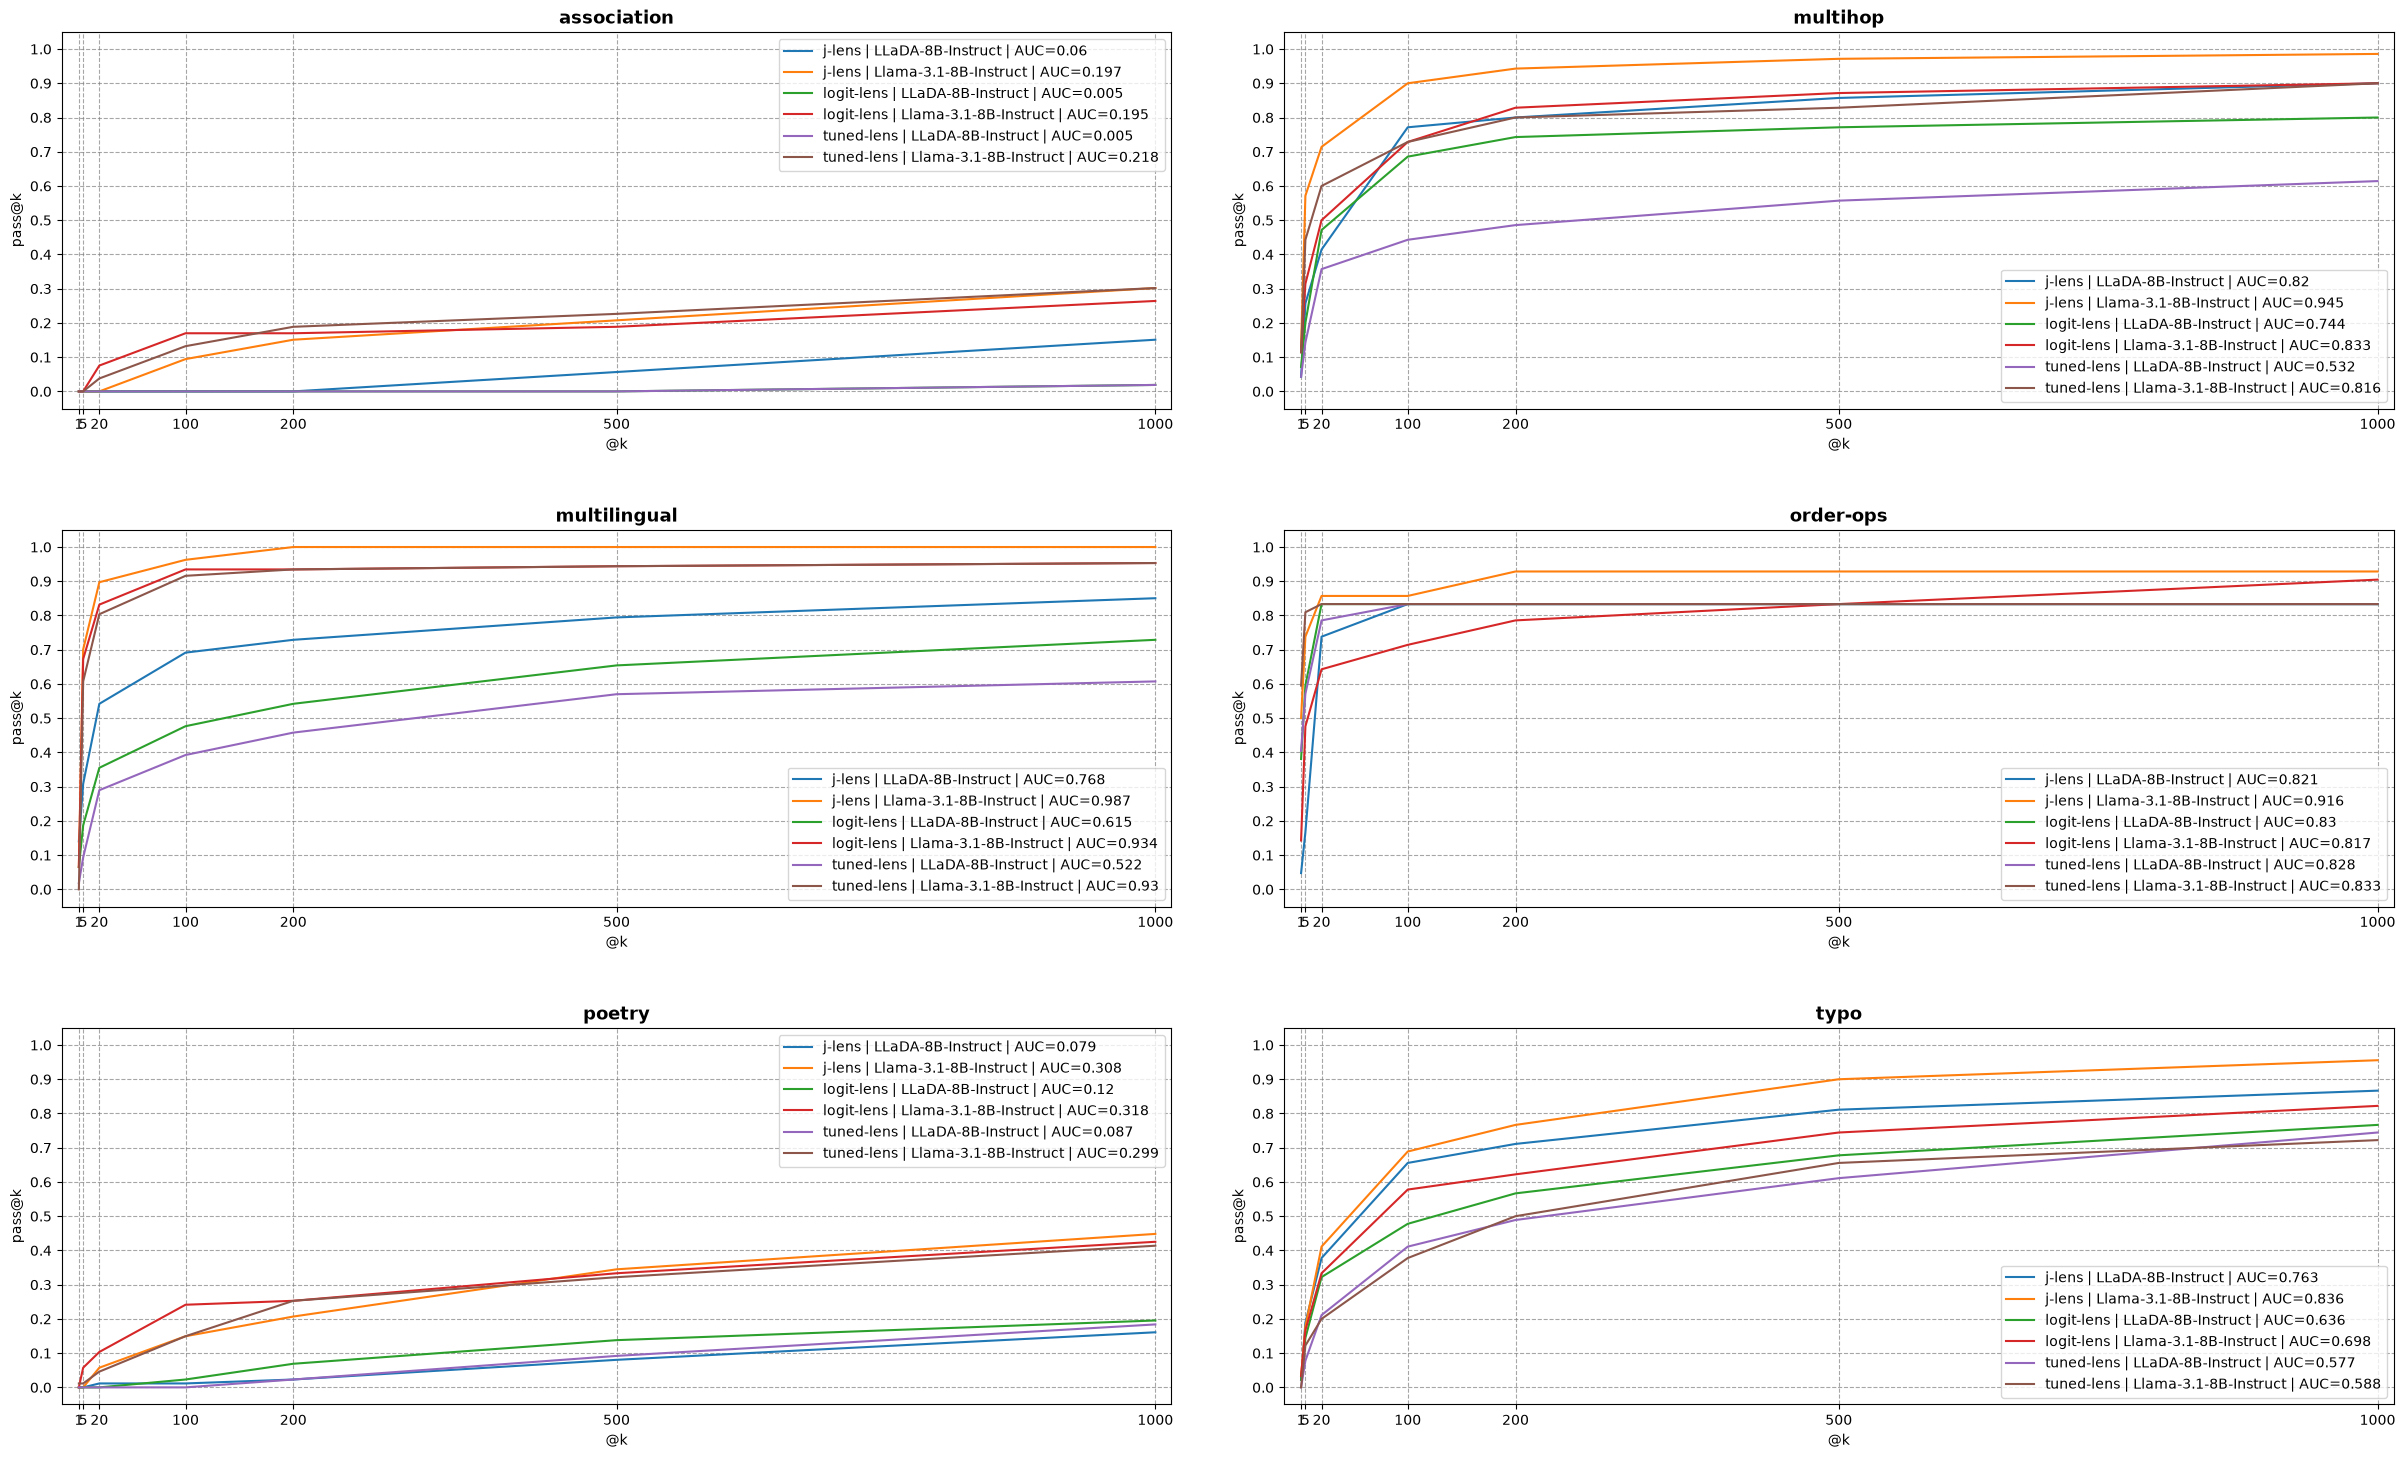

In [32]:
plot_metrics_per_method(df=single_token_results_df, at_k=at_k)

## first token

от каждого intermediate берется первый токен

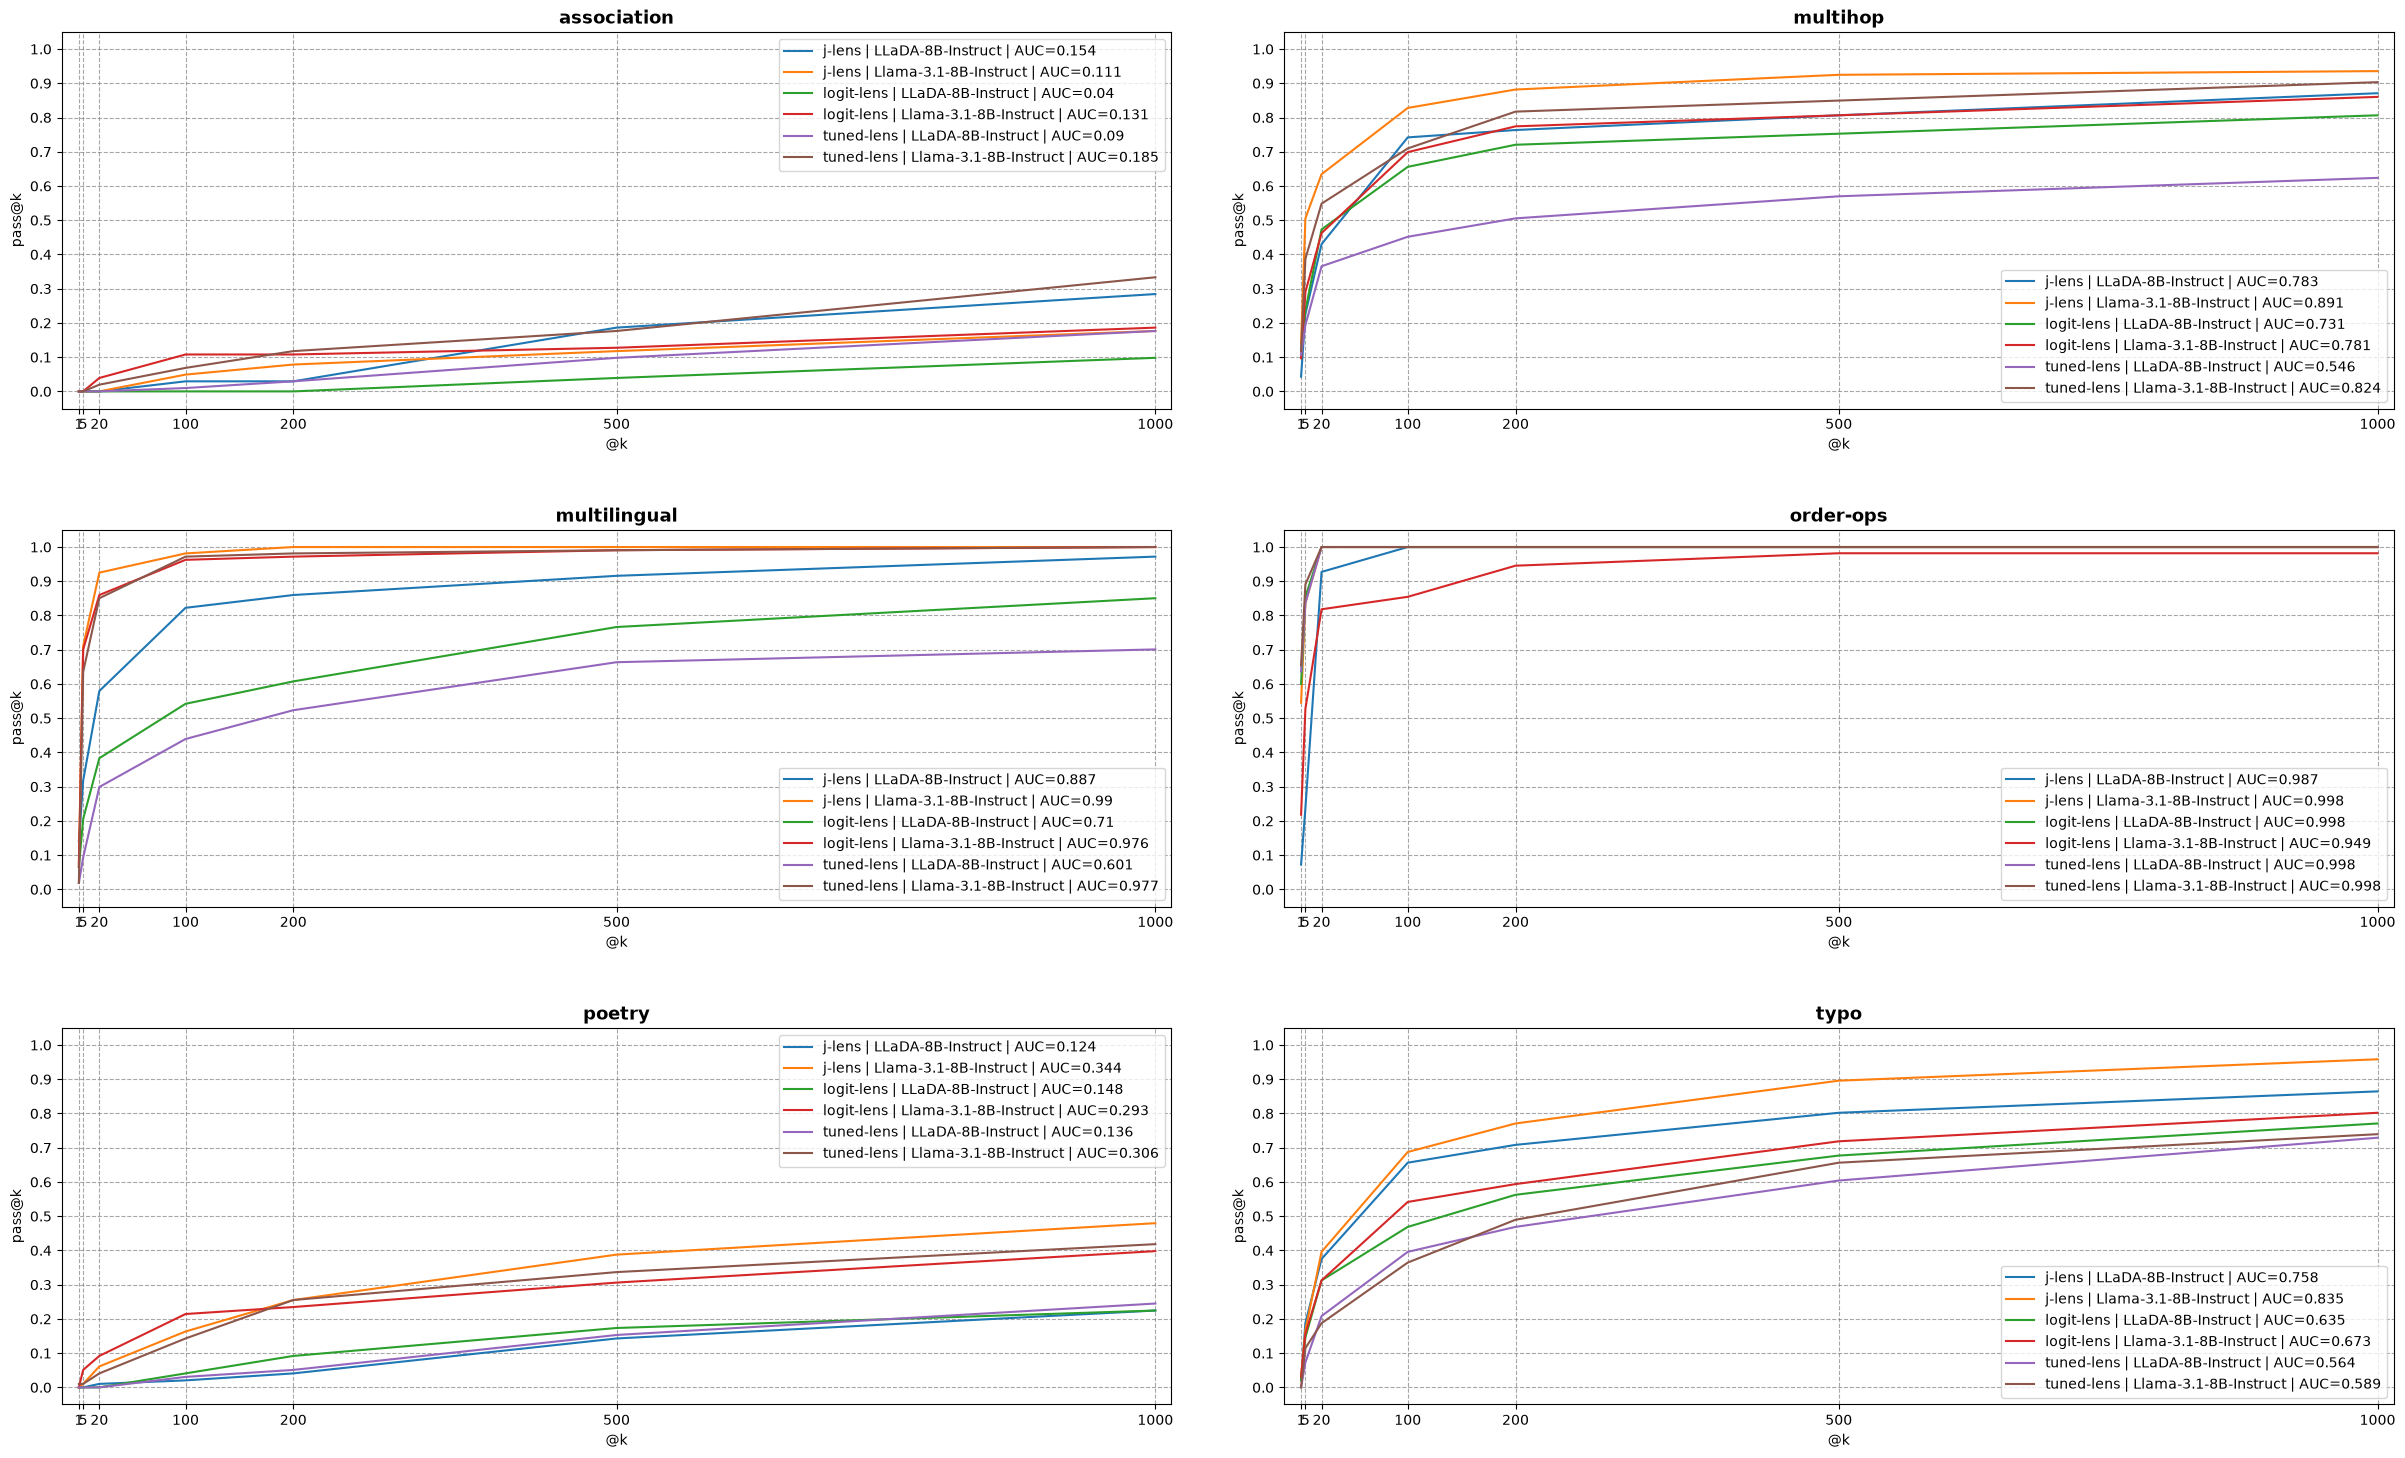

In [35]:
plot_metrics_per_method(df=first_token_results_df, at_k=at_k)